# 02 - Exploratory Data Analysis & Preprocessing
## Machine Learning Lab Project: Cryptocurrency Price Forecasting

### 🎯 Objective
1. Inspect the dataset for missing values, anomalies, or duplicated timestamps.
2. Analyze statistical properties of price and return distributions (skewness, kurtosis).
3. Investigate volatility clustering and stationarity concepts.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))
import src

# Load representative timeframe (1h)
df = src.load_timeframe_data('1h', data_dir='../data/raw')
print(f"Loaded 1h dataset: {df.shape[0]} candles.")

Loaded 1h dataset: 800 candles.


### 🧪 Data Integrity & Missing Values Check

In [2]:
null_counts = df.isnull().sum()
duplicates = df.duplicated(subset=['timestamp']).sum()

print("Missing values per column:")
print(null_counts)
print(f"\nDuplicated timestamps: {duplicates}")
print(f"Data types:\n{df.dtypes}")

Missing values per column:
timestamp    0
open         0
high         0
low          0
close        0
volume       0
dtype: int64

Duplicated timestamps: 0
Data types:
timestamp    datetime64[us]
open                float64
high                float64
low                 float64
close               float64
volume              float64
dtype: object


### 📈 Descriptive Statistics of Price and Volume

In [3]:
df[['open', 'high', 'low', 'close', 'volume']].describe().round(2)

,open,high,low,close,volume
count,800.00,800.00,800.00,800.00,800.00
mean,83252.64,83456.96,83052.21,83260.29,646.34
std,1941.20,1939.16,1929.61,1926.17,535.57
min,76402.01,76458.55,76000.00,76415.85,75.91
25%,81978.83,82158.09,81753.78,81981.98,327.56
50%,83431.51,83619.30,83208.00,83431.52,488.17
75%,84518.00,84677.08,84329.25,84518.00,780.02
max,87166.94,87395.67,86636.00,87166.95,4612.33


### 📊 Candlestick & Volume Dynamics
Visualizing high-low spreads and trade volume across time.

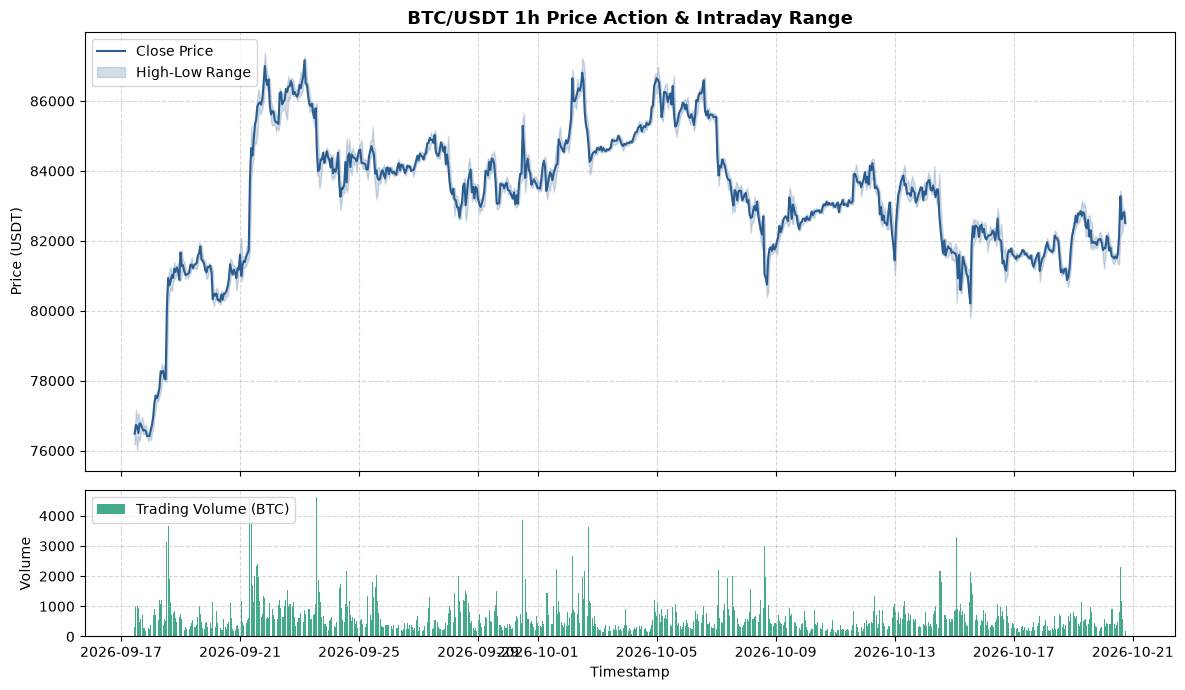

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(df['timestamp'], df['close'], label='Close Price', color='#2b5c8f', lw=1.5)
ax1.fill_between(df['timestamp'], df['low'], df['high'], color='#2b5c8f', alpha=0.2, label='High-Low Range')
ax1.set_title('BTC/USDT 1h Price Action & Intraday Range', fontsize=13, fontweight='bold')
ax1.set_ylabel('Price (USDT)')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.bar(df['timestamp'], df['volume'], color='#43aa8b', width=0.03, label='Trading Volume (BTC)')
ax2.set_ylabel('Volume')
ax2.set_xlabel('Timestamp')
ax2.legend(loc='upper left')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 📉 Log Returns & Distribution Analysis
In financial ML, raw prices are non-stationary ($I(1)$ series). We analyze percentage and log returns:
$$\text{Return}_t = \frac{P_t - P_{t-1}}{P_{t-1}}, \quad r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Log Return Statistics:
  Mean:      0.000095
  Std Dev:   0.003614
  Skewness:  0.7983 (Asymmetry)
  Kurtosis:  9.5618 (Fat-tail / Leptokurtic property)


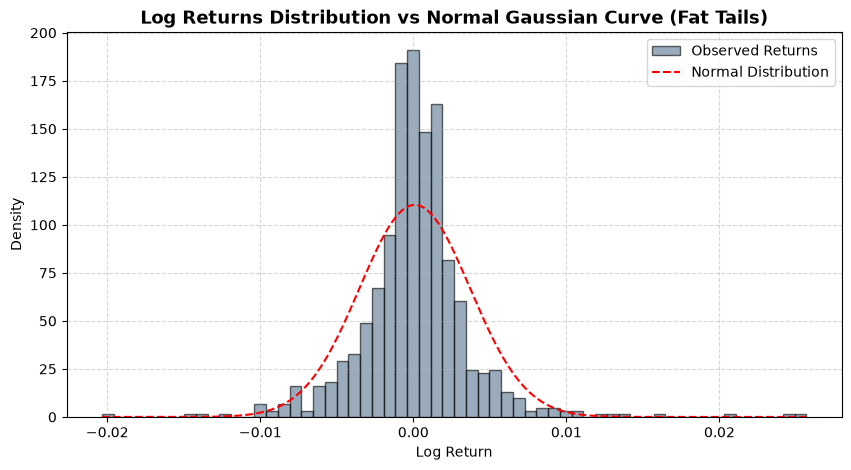

In [5]:
df['log_return'] = np.log(df['close'] / df['close'].shift(1))
clean_returns = df['log_return'].dropna()

mean_ret = clean_returns.mean()
std_ret = clean_returns.std()
skew = clean_returns.skew()
kurt = clean_returns.kurtosis()

print(f"Log Return Statistics:")
print(f"  Mean:      {mean_ret:.6f}")
print(f"  Std Dev:   {std_ret:.6f}")
print(f"  Skewness:  {skew:.4f} (Asymmetry)")
print(f"  Kurtosis:  {kurt:.4f} (Fat-tail / Leptokurtic property)")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(clean_returns, bins=60, density=True, alpha=0.6, color='#577590', edgecolor='black', label='Observed Returns')

# Overlay normal distribution
x_axis = np.linspace(clean_returns.min(), clean_returns.max(), 200)
norm_pdf = (1 / (std_ret * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_axis - mean_ret) / std_ret) ** 2)
ax.plot(x_axis, norm_pdf, 'r--', label='Normal Distribution')

ax.set_title('Log Returns Distribution vs Normal Gaussian Curve (Fat Tails)', fontsize=13, fontweight='bold')
ax.set_xlabel('Log Return')
ax.set_ylabel('Density')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 📝 Lab Summary & Preprocessing Observations
1. **Zero Missing Values:** The CCXT public spot API provides clean, continuous OHLCV data.
2. **Fat Tails (Leptokurtic):** High kurtosis confirms that extreme crypto price movements happen much more frequently than assumed by a standard bell curve.
3. **Stationarity:** Raw prices drift over time, confirming the necessity of normalized features and technical oscillators for ML models.